# 3. Calibration of the trained networks

Simulation-based calibration (SBC): for simulations drawn from the prior, record where the true parameter
falls among the posterior samples (its rank). For a calibrated network the ranks are uniform, mean 0.5.
The README figure uses 300 simulations; here 100 to keep it quick.

In [1]:
%matplotlib inline
import os, warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import torch
from scipy import stats
from GWBackFinder import Simulator
from GWBackFinder.prior import get_prior
from GWBackFinder.posterior import load_posterior, _flow_sample_in_box

N, S = 100, 500          # simulations, posterior samples per simulation
posterior_AA = load_posterior("AA_channel/posterior_AA.pkl")
posterior_TT = load_posterior("TT_channel/posterior_TT.pkl")
sim = Simulator()
torch.manual_seed(0)

In [2]:
# AA: data with the true P appended, as in training
thetas_AA = get_prior().sample((N,))
X_AA = torch.tensor(sim.simulate_AA_batch(thetas_AA.numpy(), seed=0, n_jobs=os.cpu_count()))
ranks = np.zeros((N, 28))
for i in range(N):
    s, keep = _flow_sample_in_box(posterior_AA, X_AA[i].expand(S, -1), n_dims_box=27)
    ranks[i] = (s[keep].numpy() < thetas_AA[i].numpy()).mean(0)

# TT
P = np.random.default_rng(1).normal(15, 3, (N, 1))
X_TT = torch.tensor(sim.simulate_TT_batch(P, seed=1, n_jobs=os.cpu_count()))
ranks_TT = np.array([(posterior_TT.sample((S,), x=X_TT[i], show_progress_bars=False).numpy().ravel() < P[i, 0]).mean()
                     for i in range(N)])

  0%|          | 0/100 [00:00<?, ?it/s]

100%|██████████| 100/100 [00:04<00:00, 22.97it/s]

100%|██████████| 100/100 [00:04<00:00, 22.73it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

100%|██████████| 100/100 [00:00<00:00, 177.13it/s]

100%|██████████| 100/100 [00:00<00:00, 139.80it/s]

AA parameters failing KS (p<0.01): ['3', '5', '6', 'amp', 'A']
TT KS p-value: 0.685


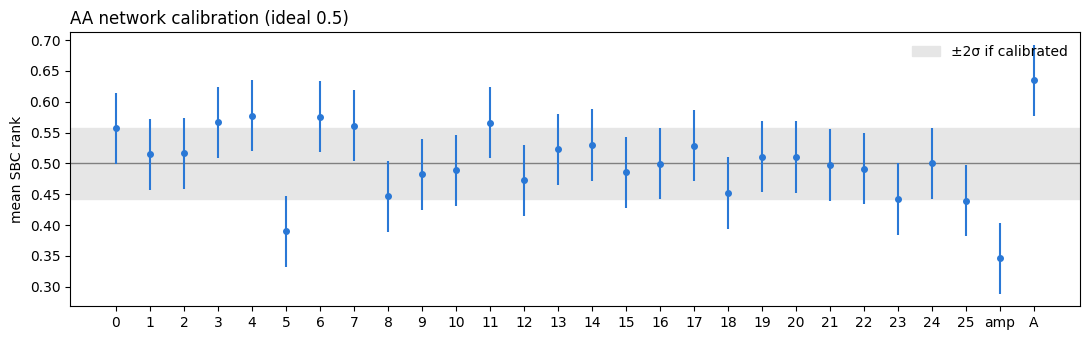

In [3]:
se = np.sqrt(1 / 12 / N)
names = [str(i) for i in range(26)] + ["amp", "A"]
pvals = [stats.kstest(ranks[:, j], "uniform").pvalue for j in range(28)]
print("AA parameters failing KS (p<0.01):", [names[j] for j in range(28) if pvals[j] < 0.01])
print("TT KS p-value:", round(stats.kstest(ranks_TT, "uniform").pvalue, 3))

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.axhspan(0.5 - 2 * se, 0.5 + 2 * se, color="0.9", label="±2σ if calibrated")
ax.axhline(0.5, color="0.5", lw=1)
ax.errorbar(np.arange(28), ranks.mean(0), yerr=2 * se, fmt="o", ms=4, color="#2a78d6", capsize=0)
ax.set_xticks(np.arange(28)); ax.set_xticklabels(names)
ax.set_ylabel("mean SBC rank"); ax.set_title("AA network calibration (ideal 0.5)", loc="left")
ax.legend(frameon=False); fig.tight_layout()